<a href="https://colab.research.google.com/github/Computercoder125/CSC121Projects/blob/main/HW5/diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HW5 – Ensemble Learning on the Pima Indians Diabetes Dataset


## Overview

This notebook predicts whether a patient has diabetes (`Outcome = 1`) from eight diagnostic measurements. The work moves through the full workflow:

1. **Load** the data and name the columns (Task 1)
2. **Inspect** structure and distributions, and spot placeholder values (Task 2)
3. **Quantify and impute** implicit missing values with `SimpleImputer` (Task 3)
4. **Build a preprocessing pipeline** with `ColumnTransformer` + `Pipeline` (Task 4)
5. **Ensembles:** Voting (Task 5), Bagging with OOB (Task 6), Random Forest (Task 7), AdaBoost (Task 8)
6. **Summary** of every model's test accuracy (Task 9, a short wrap-up)

## Parallel vs. sequential ensembles

| Family | Methods here | How base learners are trained | Main effect |
|---|---|---|---|
| **Parallel** | Voting, Bagging, Random Forest | Independently of each other | Mostly reduces **variance** |
| **Sequential** | AdaBoost | One after another; each focuses on the previous one's mistakes | Mostly reduces **bias** |

## Conventions used throughout

* **One fixed split.** The data is split once (80 % train / 20 % test, stratified, `random_state=42`). The test set is never used to fit anything, including imputation and scaling.
* **Leakage-safe preprocessing.** Imputation and scaling live inside a `Pipeline`, so they are always fitted on training data only.
* **Reproducibility.** Every random component uses `random_state=42`. Exact numbers can differ slightly across scikit-learn versions.
* **Small test set.** The test set has only 154 patients, so one patient is about 0.65 percentage points of accuracy. Small differences between models should not be over-interpreted.

## Setup: imports and plot style

### What the next cell does

* Imports `numpy`/`pandas` for data handling and `matplotlib` for plotting.
* Imports every scikit-learn tool used later: the imputer, scaler, `ColumnTransformer`, `Pipeline`, the base classifiers, and the ensemble classes (`VotingClassifier`, `BaggingClassifier`, `RandomForestClassifier`, `AdaBoostClassifier`) plus evaluation metrics.
* Defines a small colour palette and matplotlib defaults so all figures look consistent: a zero baseline for bars, light gridlines, and no top/right spines.
* Creates an empty dictionary, `results`, in which each task stores its test accuracy for the final comparison.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (VotingClassifier, BaggingClassifier,
                              RandomForestClassifier, AdaBoostClassifier)
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, brier_score_loss)
from sklearn.calibration import calibration_curve, CalibratedClassifierCV

RANDOM_STATE = 42

# ---- colour palette (colour-blind-safe categorical slots + neutral chrome)
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, SECONDARY, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
NEUTRAL = "#c3c2b7"
BLUE_CMAP = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#2a78d6", "#104281"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": BASELINE, "axes.labelcolor": SECONDARY,
    "xtick.color": SECONDARY, "ytick.color": SECONDARY, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 11, "axes.titlesize": 13,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110, "lines.linewidth": 2,
})

TARGET_NAMES = ["Non-diabetic", "Diabetic"]
results = {}   # model name -> test accuracy, filled in as we go
print("Setup complete.")

Setup complete.


## Task 1: Load the dataset into a Pandas DataFrame from the source repository or course mirror, assigning appropriate column names.



### Goal
Read the Pima Indians Diabetes data into a pandas `DataFrame` and give every column a meaningful name.

### What the following code cell does
1. **Defines the column names.** The raw UCI file has *no header row*, so the nine names are supplied by hand in the documented order: `Pregnancies`, `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, `BMI`, `DiabetesPedigreeFunction`, `Age`, and the target `Outcome`.
2. **Loads the file with `pd.read_csv(..., header=None, names=COLUMNS)`.** It first tries a public mirror of the original UCI file; if the network is unavailable it falls back to the copy saved in this folder (`pima-indians-diabetes.csv`), so the notebook runs anywhere.
3. **Sanity-checks the load** by printing the data source, the shape (expected: 768 rows × 9 columns), and the number of exact duplicate rows.

### Why it matters
Without `header=None` pandas would treat the first patient as column names and silently drop a row. Descriptive names make every later step (imputation, plotting, feature importance) readable.

### Expected results
A shape of `(768, 9)`.

In [2]:
COLUMNS = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin",
           "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"]

URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv" #use an ext
LOCAL = "pima-indians-diabetes.csv"

try:
    df = pd.read_csv(URL, header=None, names=COLUMNS)
    source = URL
except Exception as err:
    print("Could not download the file (", type(err).__name__, ") - using the local copy.")
    df = pd.read_csv(LOCAL, header=None, names=COLUMNS)
    source = LOCAL

print("Data source :", source)
print("Shape       :", df.shape, "(rows, columns)")
print("Duplicates  :", df.duplicated().sum())

Data source : https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv
Shape       : (768, 9) (rows, columns)
Duplicates  : 0


## Task 2 – Use structural inspection methods (head(), info(), describe()) to analyze feature distributions and identify non-standard placeholder values.

### Goal
Understand the shape, types, and distributions of the data, and find values that look valid but are not.

### What the following code cell does
1. **`df.head()`** shows the first rows so we can eyeball the values.
2. **`df.info()`** lists each column's dtype and non-null count. Every column is complete (no `NaN`), which is exactly why missing data is *implicit*: it is hidden in ordinary-looking numbers.
3. **`df.describe().T`** gives count, mean, std, min, quartiles, and max per feature. We look at the `min` column in particular.
4. **Counts zeros per column and the class balance.** A zero is physiologically impossible for glucose, diastolic blood pressure, skin-fold thickness, insulin, and BMI. A living patient cannot have 0 mg/dL glucose or a BMI of 0, so these zeros must be placeholders for "not measured". Zero **is** legitimate for `Pregnancies` and for `Outcome`, so those are excluded from the suspicious list.
5. **Draws a histogram for each feature.** A tall spike at 0 in `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, and `BMI` is visual confirmation of placeholders. Other features (e.g. `Age`, `DiabetesPedigreeFunction`) show a natural right-skewed shape without a spike.

### Why it matters
If we leave these zeros in, the model treats "missing" as a real, extremely low measurement. That distorts means, scaling, tree split thresholds, and distance-based models such as SVC.

### What to look for
* `min = 0` for the five suspect columns in `describe()`.
* Large zero counts for `Insulin` and `SkinThickness` and small ones for `Glucose` and `BMI`.
* The class balance (roughly 65 % non-diabetic / 35 % diabetic), which tells us accuracy alone must be interpreted alongside precision/recall.

=== head() ===


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



=== info() ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

=== describe() ===


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
Glucose,768.0,120.89,31.97,0.00,99.00,117.00,140.25,199.00
BloodPressure,768.0,69.11,19.36,0.00,62.00,72.00,80.00,122.00
SkinThickness,768.0,20.54,15.95,0.00,0.00,23.00,32.00,99.00
Insulin,768.0,79.80,115.24,0.00,0.00,30.50,127.25,846.00
BMI,768.0,31.99,7.88,0.00,27.30,32.00,36.60,67.10
DiabetesPedigreeFunction,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00
Outcome,768.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00



=== Zeros per feature (Pregnancies and Outcome zeros are legitimate) ===


,zeros,percent
Pregnancies,111,14.5
Glucose,5,0.7
BloodPressure,35,4.6
SkinThickness,227,29.6
Insulin,374,48.7
BMI,11,1.4
DiabetesPedigreeFunction,0,0.0
Age,0,0.0



=== Class balance ===


,patients,percent
Outcome,,
0 (non-diabetic),500,65.1
1 (diabetic),268,34.9


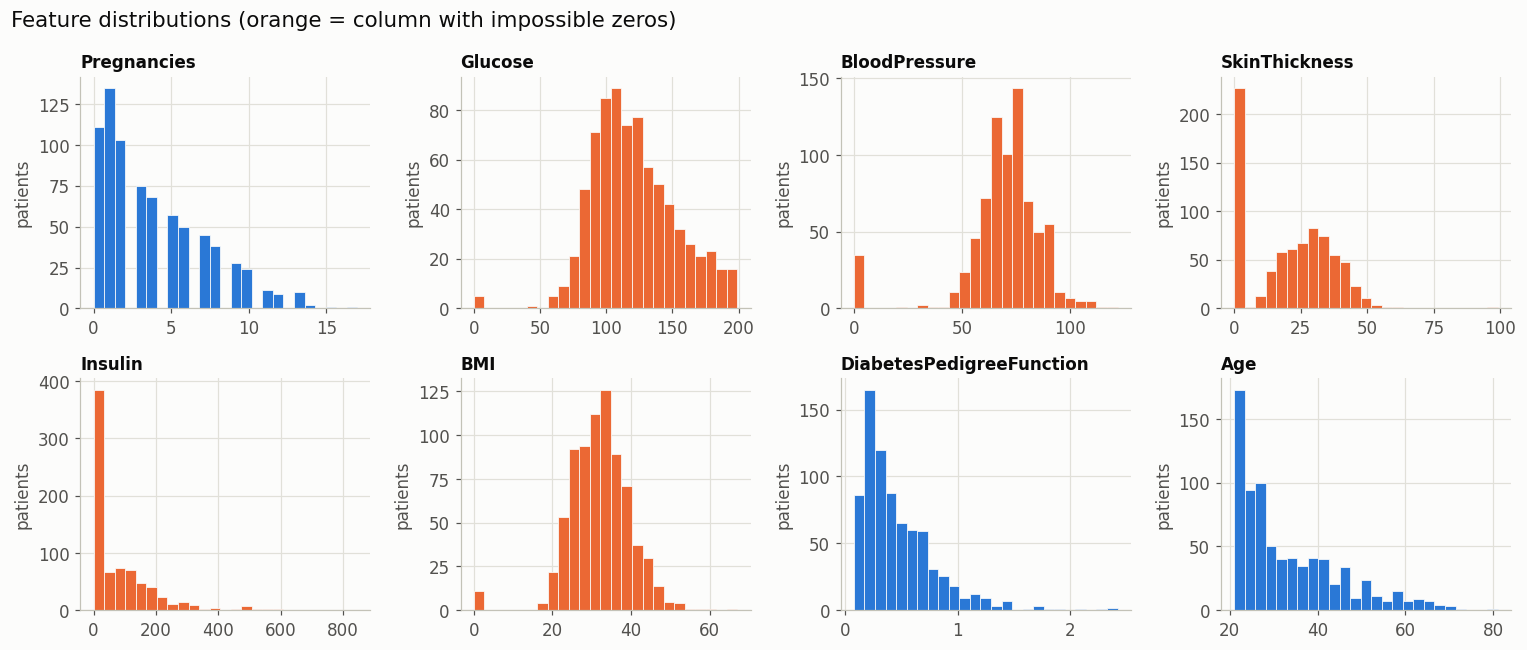

In [5]:
print("=== head() ===")
display(df.head())

print("\n=== info() ===")
df.info()

print("\n=== describe() ===")
display(df.describe().T.round(2))

suspect = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
zero_table = pd.DataFrame({
    "zeros": (df.drop(columns="Outcome") == 0).sum(),
    "percent": ((df.drop(columns="Outcome") == 0).mean() * 100).round(1),
})
print("\n=== Zeros per feature (Pregnancies and Outcome zeros are legitimate) ===")
display(zero_table)

print("\n=== Class balance ===")
display(df["Outcome"].value_counts().rename({0: "0 (non-diabetic)", 1: "1 (diabetic)"}).to_frame("patients")
        .assign(percent=lambda t: (t["patients"] / len(df) * 100).round(1)))

features = [c for c in df.columns if c != "Outcome"]
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, col in zip(axes.ravel(), features):
    ax.hist(df[col], bins=25, color=ORANGE if col in suspect else BLUE, edgecolor=SURFACE, linewidth=0.5)
    ax.set_title(col, fontsize=11)
    ax.set_ylabel("patients")
fig.suptitle("Feature distributions (orange = column with impossible zeros)", x=0.01, ha="left", fontsize=14)
fig.tight_layout()
plt.show()

## Task 3 – Quantify and handle implicit missing values using SimpleImputer.

### Goal
Turn the hidden placeholder zeros into explicit missing values, measure how much is missing, and impute them properly.

### What the following code cell does
1. **Converts impossible zeros to `NaN`** in the five suspect columns (`Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, `BMI`). `Pregnancies` is left alone because 0 is a real value there.
2. **Quantifies the missingness** per column (count and percent) and draws a bar chart of it.
3. **Compares two ways of handling it.**
   * *Row deletion* (`dropna()`): the code reports how many patients would remain. Deleting every patient with any missing value throws away a large share of an already small dataset and can bias it, because the missingness is not random (e.g. insulin is often skipped for patients who were not tested).
   * *Imputation*: keeps all patients by filling each gap with a typical value.
4. **Checks skewness** of the suspect columns to choose between mean and median imputation. Several are right-skewed, so the **median** is more robust than the mean (outliers do not pull it).
5. **Splits the data first (80 / 20, stratified).** The imputer is then **fitted on the training set only** and applied to both sets. This prevents *data leakage* of information from the test set into training.
6. **Verifies the result:** no `NaN` remains, and the learned medians are printed.

### Why it matters
Missing data handled badly is one of the most common sources of silently wrong results in medical machine learning. This step also fixes the train/test split used by every later task.

### Expected results
* `Insulin` and `SkinThickness` have by far the most missing values.
* The number of rows that would survive `dropna()` is much smaller than 768.
* After imputation the missing counts are zero in both train and test.

=== Missing values after converting zeros to NaN ===


,missing,percent
Glucose,5,0.7
BloodPressure,35,4.6
SkinThickness,227,29.6
Insulin,374,48.7
BMI,11,1.4


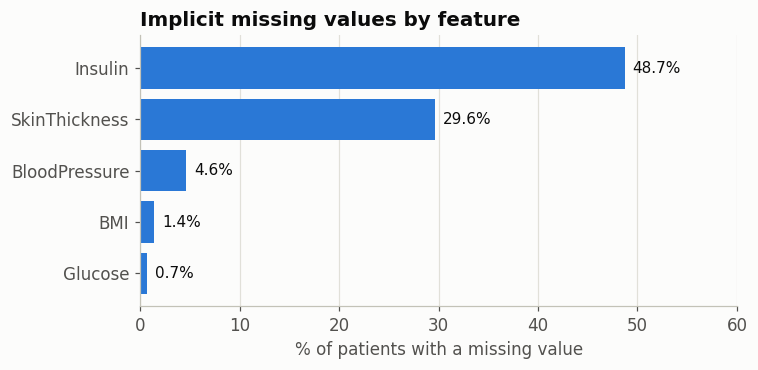

Rows kept if we delete every patient with any missing value: 392 of 768 (51.0%); we would lose 376 patients.

=== Skewness / mean / median of observed values ===


,skew,mean,median
Glucose,0.53,121.7,117.0
BloodPressure,0.13,72.4,72.0
SkinThickness,0.69,29.2,29.0
Insulin,2.17,155.5,125.0
BMI,0.59,32.5,32.3



Train: (614, 8), Test: (154, 8); diabetic share train/test = 0.349 / 0.351

Medians learned from the TRAINING set:
{'Glucose': 117.0, 'BloodPressure': 72.0, 'SkinThickness': 29.0, 'Insulin': 125.0, 'BMI': 32.4}

Missing values left  -> train: 0 | test: 0


In [6]:
suspect = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

# 1) Make the implicit missing values explicit
df_nan = df.copy()
df_nan[suspect] = df_nan[suspect].replace(0, np.nan)

# 2) Quantify
missing = pd.DataFrame({"missing": df_nan[suspect].isna().sum(),
                        "percent": (df_nan[suspect].isna().mean() * 100).round(1)})
print("=== Missing values after converting zeros to NaN ===")
display(missing)

fig, ax = plt.subplots(figsize=(7, 3.2))
order = missing.sort_values("percent")
bars = ax.barh(order.index, order["percent"], color=BLUE)
for b, v in zip(bars, order["percent"]):
    ax.text(v + 0.8, b.get_y() + b.get_height() / 2, f"{v:.1f}%", va="center", fontsize=10)
ax.set_xlim(0, 60); ax.set_xlabel("% of patients with a missing value")
ax.set_title("Implicit missing values by feature"); ax.grid(axis="y", visible=False)
plt.show()

# 3) What would row deletion cost?
kept = len(df_nan.dropna())
print(f"Rows kept if we delete every patient with any missing value: {kept} of {len(df_nan)} "
      f"({kept / len(df_nan):.1%}); we would lose {len(df_nan) - kept} patients.")

# 4) Mean vs median: skewness of the observed (non-missing) values
print("\n=== Skewness / mean / median of observed values ===")
display(pd.DataFrame({"skew": df_nan[suspect].skew().round(2),
                      "mean": df_nan[suspect].mean().round(1),
                      "median": df_nan[suspect].median().round(1)}))

# 5) Split FIRST, then fit the imputer on the training data only
X = df_nan.drop(columns="Outcome")
y = df_nan["Outcome"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"\nTrain: {X_train.shape}, Test: {X_test.shape}; diabetic share train/test = "
      f"{y_train.mean():.3f} / {y_test.mean():.3f}")

imputer = SimpleImputer(strategy="median")
imputer.fit(X_train[suspect])
print("\nMedians learned from the TRAINING set:")
print({c: float(round(v, 1)) for c, v in zip(suspect, imputer.statistics_)})

X_train_imp = X_train.copy(); X_test_imp = X_test.copy()
X_train_imp[suspect] = imputer.transform(X_train[suspect])
X_test_imp[suspect] = imputer.transform(X_test[suspect])

# 6) Verify
print("\nMissing values left  -> train:", int(X_train_imp.isna().sum().sum()),
      "| test:", int(X_test_imp.isna().sum().sum()))

## Task 4 – Build a Scikit-Learn ColumnTransformer and Pipeline that applies appropriate scaling.

### Goal
Package imputation and scaling into one reusable, leakage-safe object that every model in the rest of the notebook will use.

### What the following code cell does
1. **Splits the columns into two groups.**
   * *Group A* – the five columns with implicit missing values: median `SimpleImputer` → `StandardScaler`.
   * *Group B* – the remaining columns (`Pregnancies`, `DiabetesPedigreeFunction`, `Age`): `StandardScaler` only.
2. **Combines them with `ColumnTransformer`.** Each group gets its own sub-pipeline, and the outputs are concatenated. `verbose_feature_names_out=False` keeps the original column names.
3. **Fits the transformer on the training data only** and transforms both sets. The code displays the transformed training data and checks that the training mean is about 0 and the standard deviation about 1.
4. **Defines `make_pipe(model)`**, a helper that returns `Pipeline([preprocessor, model])`. A fresh clone of the preprocessor is used each time, so every model is trained with preprocessing learned from training data only, and cross-validation or bagging cannot leak test information.
5. **Fits a baseline Logistic Regression pipeline** as a first end-to-end check and as a reference accuracy.

### Why standardise?
`StandardScaler` rescales each feature to mean 0 and unit variance. It matters for the scale-sensitive models: Logistic Regression (regularisation and optimiser convergence) and SVC with an RBF kernel (distance-based, so a large-range feature such as `Insulin` would dominate). Tree-based models are scale-invariant, so scaling neither helps nor hurts them, and using one common pipeline keeps the comparison fair.

### Expected results
Training means near 0 and standard deviations near 1 in the transformed table, and a baseline test accuracy that later models will try to beat.

In [7]:
impute_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
other_cols = [c for c in X_train.columns if c not in impute_cols]

impute_and_scale = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("impute_scale", impute_and_scale, impute_cols),
        ("scale_only", StandardScaler(), other_cols),
    ],
    verbose_feature_names_out=False,
)

# Fit on TRAIN only, transform both
Xtr_t = preprocessor.fit_transform(X_train)
Xte_t = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

train_view = pd.DataFrame(Xtr_t, columns=feature_names)
print("Transformed training data (first 5 rows):")
display(train_view.head().round(3))
print("Training mean (should be ~0):\n", train_view.mean().round(3).to_dict())
print("Training std  (should be ~1):\n", train_view.std(ddof=0).round(3).to_dict())
print("NaNs left after transform:", int(np.isnan(Xtr_t).sum() + np.isnan(Xte_t).sum()))


def make_pipe(model):
    # Full pipeline: fresh preprocessing + the given model.
    return Pipeline([("prep", clone(preprocessor)), ("model", model)])


baseline = make_pipe(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)).fit(X_train, y_train)
results["Logistic Regression (baseline)"] = baseline.score(X_test, y_test)
print(f"\nBaseline Logistic Regression test accuracy: {results['Logistic Regression (baseline)']:.3f}")

Transformed training data (first 5 rows):


,Glucose,BloodPressure,SkinThickness,Insulin,BMI,Pregnancies,DiabetesPedigreeFunction,Age
0,-1.056,-0.827,-1.918,-1.203,-0.770,-0.851,0.311,-0.792
1,0.144,0.478,-0.230,-1.470,-0.418,0.357,-0.116,0.561
2,-0.556,-1.153,1.233,-0.555,0.360,-0.549,-0.765,-0.708
3,0.812,-1.316,-0.005,-0.161,-0.403,-0.851,0.262,-0.369
4,-0.890,-0.664,1.121,-0.416,1.782,-1.153,-0.338,-0.961


Training mean (should be ~0):
 {'Glucose': -0.0, 'BloodPressure': 0.0, 'SkinThickness': -0.0, 'Insulin': -0.0, 'BMI': 0.0, 'Pregnancies': -0.0, 'DiabetesPedigreeFunction': -0.0, 'Age': -0.0}
Training std  (should be ~1):
 {'Glucose': 1.0, 'BloodPressure': 1.0, 'SkinThickness': 1.0, 'Insulin': 1.0, 'BMI': 1.0, 'Pregnancies': 1.0, 'DiabetesPedigreeFunction': 1.0, 'Age': 1.0}
NaNs left after transform: 0

Baseline Logistic Regression test accuracy: 0.708


Task 5: Train both a Hard Voting Classifier and a Soft Voting Classifier combining base models (e.g., Logistic Regression, Support Vector Classifier, and a Decision Tree), then evaluate their test accuracy and classification reports. Use must use appropriate plots to show the results.

### Goal
Combine three *different* kinds of models and compare two ways of aggregating their decisions.

### Base models
* **Logistic Regression** – linear decision boundary, well-calibrated probabilities.
* **Support Vector Classifier (RBF)** – flexible non-linear boundary. An SVC natively outputs margins, not probabilities, so it is wrapped in `CalibratedClassifierCV` (Platt scaling fitted with 5-fold cross-validation). This is what lets it take part in soft voting. (`SVC(probability=True)` does essentially the same internally but is deprecated in recent scikit-learn.)
* **Decision Tree (`max_depth=4`)** – interpretable rule-based model; limited depth to avoid memorising the training set.

### What the following code cell does
1. **Trains each base model alone** (inside the preprocessing pipeline) to get individual reference accuracies.
2. **Hard voting** (`voting="hard"`): each model casts one vote for a class label and the **majority label wins**. Probabilities are ignored.
3. **Soft voting** (`voting="soft"`): each model outputs class probabilities, the probabilities are **averaged**, and the class with the highest average wins. A confident model can therefore outweigh two unsure ones.
4. **Evaluates both on the held-out test set:** accuracy plus a full `classification_report` (precision, recall, F1 per class).
5. **Draws three plots**
   * a horizontal bar chart of test accuracy for the three base models and the two ensembles;
   * side-by-side confusion matrices for hard vs. soft voting, to see *which kinds* of mistakes each makes (false negatives are the costly ones in diagnosis);
   * a **calibration (reliability) curve** for each base model with its Brier score. It shows how trustworthy each model's probabilities are, which is the key assumption behind soft voting.

### Expected results
* Whether either ensemble beats its best individual member.
* How many diabetic patients each ensemble misses (bottom-left cell of the confusion matrix).
* Which base model's calibration curve is furthest from the diagonal (the decision tree typically produces coarse, over-confident probabilities).

Test accuracy:
  Logistic Regression       0.708
  SVC (RBF)                 0.740
  Decision Tree (depth 4)   0.786
  Hard Voting               0.740
  Soft Voting               0.734

===== Hard Voting - classification report =====
              precision    recall  f1-score   support

Non-diabetic      0.778     0.840     0.808       100
    Diabetic      0.652     0.556     0.600        54

    accuracy                          0.740       154
   macro avg      0.715     0.698     0.704       154
weighted avg      0.734     0.740     0.735       154


===== Soft Voting - classification report =====
              precision    recall  f1-score   support

Non-diabetic      0.771     0.840     0.804       100
    Diabetic      0.644     0.537     0.586        54

    accuracy                          0.734       154
   macro avg      0.708     0.689     0.695       154
weighted avg      0.726     0.734     0.727       154



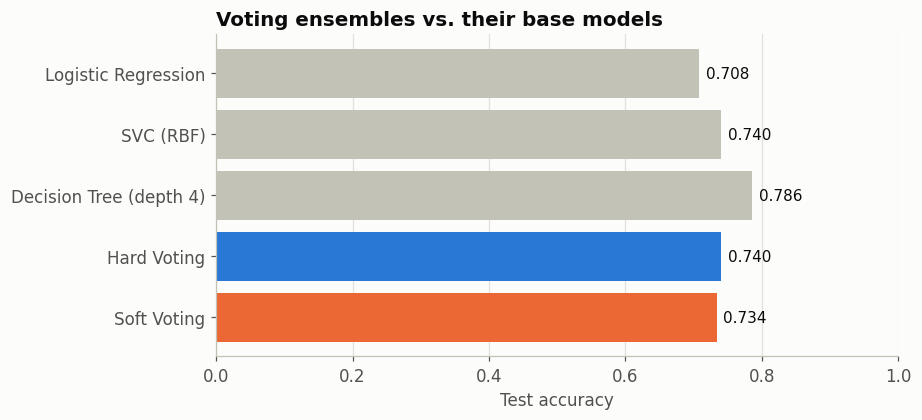

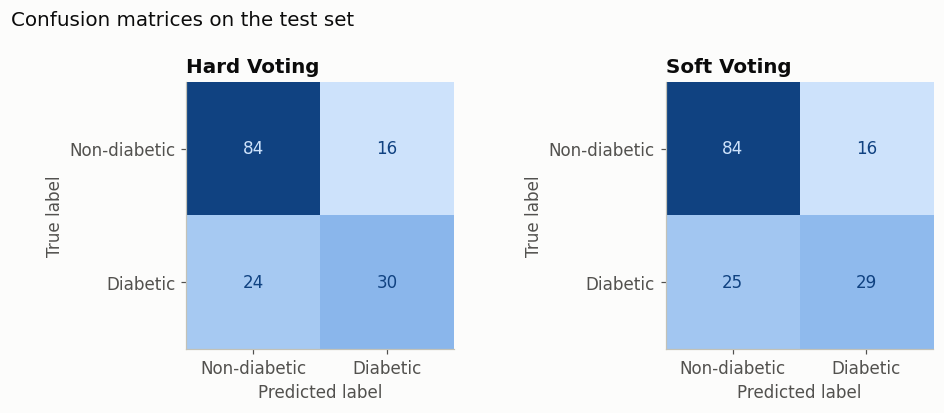

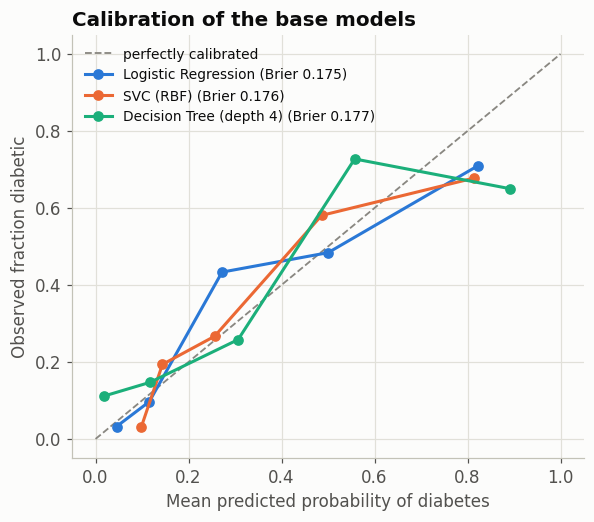

Brier score of the soft-voting ensemble: 0.168 (lower is better)


In [8]:
base_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "SVC (RBF)": CalibratedClassifierCV(SVC(kernel="rbf", random_state=RANDOM_STATE),
                                        method="sigmoid", cv=5, ensemble=False),
    "Decision Tree (depth 4)": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
}
vote_estimators = [("lr", base_models["Logistic Regression"]),
                   ("svc", base_models["SVC (RBF)"]),
                   ("dt", base_models["Decision Tree (depth 4)"])]

# Individual models
fitted = {name: make_pipe(clone(m)).fit(X_train, y_train) for name, m in base_models.items()}

# Hard and soft voting
hard_vote = make_pipe(VotingClassifier(vote_estimators, voting="hard")).fit(X_train, y_train)
soft_vote = make_pipe(VotingClassifier(vote_estimators, voting="soft")).fit(X_train, y_train)

preds = {name: p.predict(X_test) for name, p in fitted.items()}
preds["Hard Voting"] = hard_vote.predict(X_test)
preds["Soft Voting"] = soft_vote.predict(X_test)
accs = {name: accuracy_score(y_test, p) for name, p in preds.items()}
results["Hard Voting"] = accs["Hard Voting"]
results["Soft Voting"] = accs["Soft Voting"]

print("Test accuracy:")
for name, a in accs.items():
    print(f"  {name:<26s}{a:.3f}")

for name in ["Hard Voting", "Soft Voting"]:
    print(f"\n===== {name} - classification report =====")
    print(classification_report(y_test, preds[name], target_names=TARGET_NAMES, digits=3))

# ---- Plot 1: accuracy comparison
names = list(accs.keys())
colors = [NEUTRAL, NEUTRAL, NEUTRAL, BLUE, ORANGE]
fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.barh(names[::-1], [accs[n] for n in names][::-1], color=colors[::-1])
for b in bars:
    ax.text(b.get_width() + 0.01, b.get_y() + b.get_height() / 2, f"{b.get_width():.3f}", va="center", fontsize=10)
ax.set_xlim(0, 1); ax.set_xlabel("Test accuracy")
ax.set_title("Voting ensembles vs. their base models"); ax.grid(axis="y", visible=False)
plt.show()

# ---- Plot 2: confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, name in zip(axes, ["Hard Voting", "Soft Voting"]):
    ConfusionMatrixDisplay.from_predictions(y_test, preds[name], display_labels=TARGET_NAMES,
                                            cmap=BLUE_CMAP, ax=ax, colorbar=False)
    ax.set_title(name); ax.grid(False)
fig.suptitle("Confusion matrices on the test set", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
plt.show()

# ---- Plot 3: calibration of the base models
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], linestyle="--", color=MUTED, linewidth=1.2, label="perfectly calibrated")
for (name, pipe), col in zip(fitted.items(), [BLUE, ORANGE, AQUA]):
    prob = pipe.predict_proba(X_test)[:, 1]
    frac_pos, mean_pred = calibration_curve(y_test, prob, n_bins=5, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", color=col,
            label=f"{name} (Brier {brier_score_loss(y_test, prob):.3f})")
ax.set_xlabel("Mean predicted probability of diabetes"); ax.set_ylabel("Observed fraction diabetic")
ax.set_title("Calibration of the base models"); ax.legend(frameon=False, fontsize=9, loc="upper left")
plt.show()
print("Brier score of the soft-voting ensemble:",
      round(brier_score_loss(y_test, soft_vote.predict_proba(X_test)[:, 1]), 3), "(lower is better)")

Task 6: Train a Bagging Classifier using decision tree base estimators with bootstrap sampling enabled and out-of-bag evaluation, and compare the OOB score against held-out test accuracy. Plot the accuracy results in one graph.



### Goal
Train a bagged ensemble of decision trees and compare its **OOB score** with its **held-out test accuracy**.

### Background
*Bagging* (bootstrap aggregating) trains many trees, each on a **bootstrap sample**: a random sample of the training rows drawn *with replacement*. On average each bootstrap contains about 63 % of the distinct training rows, so roughly **37 % are left out ("out-of-bag")** for that tree. Predicting each training row using only the trees that never saw it gives a built-in, nearly free estimate of generalisation accuracy without a separate validation set.

### What the following code cell does
1. **Fits a single unpruned decision tree** as a reference to show how much variance bagging removes.
2. **Fits a `BaggingClassifier`** with 200 fully grown `DecisionTreeClassifier` base estimators, `bootstrap=True` and `oob_score=True`, inside the preprocessing pipeline.
3. **Reads `oob_score_`** and computes test accuracy, then prints both side by side.
4. **Sweeps the number of trees** (25 to 500) on the preprocessed data and records OOB score and test accuracy at each size.
5. **Plots OOB accuracy and test accuracy in one graph** against the number of trees, with the single tree as a dashed reference line.

### Expected results
* Bagging should clearly beat the single deep tree, because averaging many high-variance trees cancels much of their noise.
* The OOB score and the test accuracy should be close. They are two independent estimates of the same quantity, which is why OOB is a useful validation tool. Small gaps are expected from the small test set.
* Both curves flatten as trees are added: more trees reduce variance but cannot fix bias.

Single decision tree test accuracy : 0.669
Bagging OOB score (train only)     : 0.748
Bagging held-out test accuracy     : 0.740
Absolute gap |OOB - test|          : 0.007


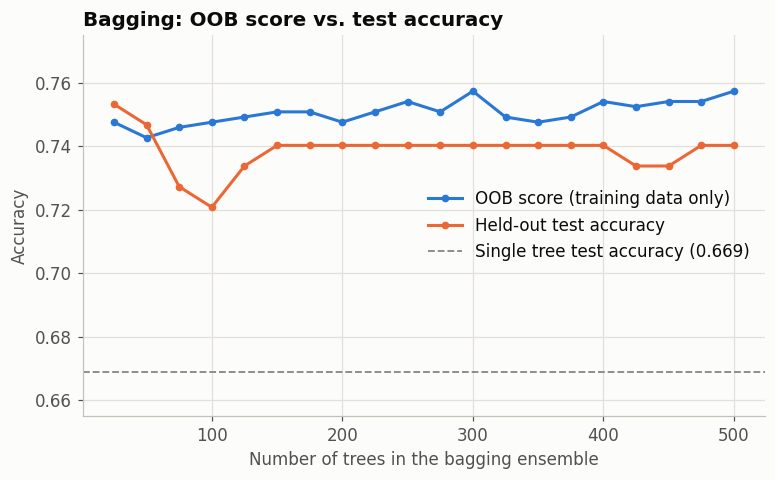

In [9]:
# Reference: one fully grown tree
single_tree = make_pipe(DecisionTreeClassifier(random_state=RANDOM_STATE)).fit(X_train, y_train)
single_acc = single_tree.score(X_test, y_test)

# Bagging with OOB evaluation
bag = make_pipe(BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
    n_estimators=200, bootstrap=True, oob_score=True,
    n_jobs=-1, random_state=RANDOM_STATE)).fit(X_train, y_train)

oob_acc = bag.named_steps["model"].oob_score_
bag_test = bag.score(X_test, y_test)
results["Single Decision Tree"] = single_acc
results["Bagging (200 trees)"] = bag_test

print(f"Single decision tree test accuracy : {single_acc:.3f}")
print(f"Bagging OOB score (train only)     : {oob_acc:.3f}")
print(f"Bagging held-out test accuracy     : {bag_test:.3f}")
print(f"Absolute gap |OOB - test|          : {abs(oob_acc - bag_test):.3f}")

# Sweep over the number of trees (preprocessing fitted once on the training data)
prep = clone(preprocessor).fit(X_train)
Xtr_p, Xte_p = prep.transform(X_train), prep.transform(X_test)
sizes = list(range(25, 501, 25))
oob_curve, test_curve = [], []
for n in sizes:
    b = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
                          n_estimators=n, bootstrap=True, oob_score=True,
                          n_jobs=-1, random_state=RANDOM_STATE).fit(Xtr_p, y_train)
    oob_curve.append(b.oob_score_)
    test_curve.append(b.score(Xte_p, y_test))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(sizes, oob_curve, color=BLUE, marker="o", markersize=4, label="OOB score (training data only)")
ax.plot(sizes, test_curve, color=ORANGE, marker="o", markersize=4, label="Held-out test accuracy")
ax.axhline(single_acc, color=MUTED, linestyle="--", linewidth=1.2, label=f"Single tree test accuracy ({single_acc:.3f})")
ax.set_xlabel("Number of trees in the bagging ensemble"); ax.set_ylabel("Accuracy")
ax.set_title("Bagging: OOB score vs. test accuracy")
ax.set_ylim(0.655, 0.775)
ax.legend(frameon=False, loc="center right")
plt.show()

Task 7: Train a Random Forest Classifier configured with feature subsetting, evaluate its test performance, and generate a horizontal bar plot visualizing feature importances (Mean Decrease in Impurity).

### Goal
Train a Random Forest, evaluate it on the test set, and visualise which features it relies on.

### Background
A Random Forest is bagging **plus one extra source of randomness**: at *every split* in *every tree*, only a random subset of the features (`max_features`) is considered. With `max_features="sqrt"`, each split looks at about √8 ≈ 2 of the 8 features. This forces the trees to use different features, so their errors are less correlated, and averaging less-correlated trees reduces variance more than averaging near-identical ones.

### What the following code cell does
1. **Fits `RandomForestClassifier`** with 300 trees, `max_features="sqrt"` and `oob_score=True`, in the preprocessing pipeline.
2. **Evaluates it:** test accuracy, OOB score, and the full `classification_report`.
3. **Extracts `feature_importances_`.** This is the *Mean Decrease in Impurity (MDI)*: for each feature, the total reduction in Gini impurity produced by splits on that feature, averaged over all trees and normalised to sum to 1.
4. **Draws a horizontal bar plot** of the importances sorted from most to least important, with values labelled.
5. **Runs a small `max_features` experiment** (1, 2, 4, and 8 features per split). The value 8 means *every* feature is considered at every split, which is plain bagging of trees, so the table shows directly what feature subsetting adds.

### Expected results
* Test accuracy compared with the single tree and with bagging from Task 6.
* Clinically sensible rankings: glucose should be near the top, followed typically by BMI and age.
* A caveat: MDI is computed on training data and tends to favour continuous, high-cardinality features, so treat it as a guide, not as proof of causation.

Random Forest test accuracy: 0.734
Random Forest OOB score    : 0.757

              precision    recall  f1-score   support

Non-diabetic      0.776     0.830     0.802       100
    Diabetic      0.638     0.556     0.594        54

    accuracy                          0.734       154
   macro avg      0.707     0.693     0.698       154
weighted avg      0.728     0.734     0.729       154

Feature importances (MDI):
Glucose                     0.270
BMI                         0.156
Age                         0.125
DiabetesPedigreeFunction    0.123
Insulin                     0.090
BloodPressure               0.082
Pregnancies                 0.081
SkinThickness               0.073


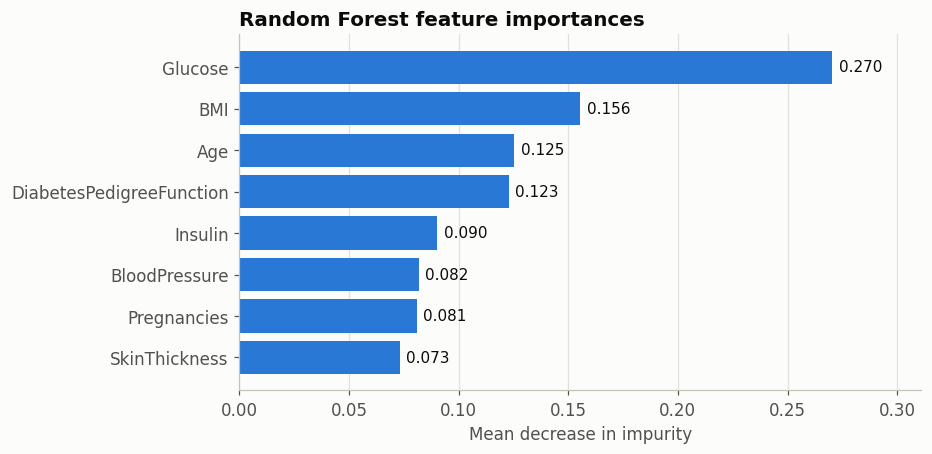


Effect of the feature-subset size:


,max_features,meaning,OOB score,test accuracy
0,1,1 random feature(s) per split,0.761,0.734
1,2,2 random feature(s) per split,0.757,0.734
2,4,4 random feature(s) per split,0.756,0.740
3,8,all features (= bagging),0.754,0.734


In [10]:
rf = make_pipe(RandomForestClassifier(
    n_estimators=300, max_features="sqrt", oob_score=True,
    n_jobs=-1, random_state=RANDOM_STATE)).fit(X_train, y_train)

rf_model = rf.named_steps["model"]
rf_pred = rf.predict(X_test)
rf_test = accuracy_score(y_test, rf_pred)
results["Random Forest"] = rf_test

print(f"Random Forest test accuracy: {rf_test:.3f}")
print(f"Random Forest OOB score    : {rf_model.oob_score_:.3f}\n")
print(classification_report(y_test, rf_pred, target_names=TARGET_NAMES, digits=3))

# ---- Feature importances (Mean Decrease in Impurity)
names_out = rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf_model.feature_importances_, index=names_out).sort_values()
print("Feature importances (MDI):")
print(imp.sort_values(ascending=False).round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.barh(imp.index, imp.values, color=BLUE)
for b in bars:
    ax.text(b.get_width() + 0.003, b.get_y() + b.get_height() / 2, f"{b.get_width():.3f}", va="center", fontsize=10)
ax.set_xlim(0, imp.max() * 1.15); ax.set_xlabel("Mean decrease in impurity")
ax.set_title("Random Forest feature importances"); ax.grid(axis="y", visible=False)
plt.show()

# ---- Effect of feature subsetting (max_features = 8 is plain bagging of trees)
rows = []
for mf in [1, 2, 4, 8]:
    m = RandomForestClassifier(n_estimators=300, max_features=mf, oob_score=True,
                               n_jobs=-1, random_state=RANDOM_STATE).fit(Xtr_p, y_train)
    rows.append({"max_features": mf,
                 "meaning": "all features (= bagging)" if mf == 8 else f"{mf} random feature(s) per split",
                 "OOB score": round(m.oob_score_, 3),
                 "test accuracy": round(m.score(Xte_p, y_test), 3)})
print("\nEffect of the feature-subset size:")
display(pd.DataFrame(rows))

Task 8: Train an AdaBoost Classifier utilizing decision stumps and sequential sample weighting, and evaluate its training versus test performance to observe potential boosting generalization trends. Plot the results.

### Goal
Train a *sequential* ensemble and study how training and test accuracy evolve as more weak learners are added.

### Background
**AdaBoost** (Adaptive Boosting) builds its learners one after another:
1. Every training sample starts with equal weight.
2. A **decision stump** (a tree of depth 1, a single yes/no question) is trained on the weighted data.
3. Its weighted error rate is measured. The stump receives a vote weight (`estimator_weights_`) that is larger when its error is smaller.
4. The weights of **misclassified samples are increased** and those of correctly classified samples decreased, so the next stump concentrates on the hard cases.
5. The final prediction is a weighted vote of all stumps. `learning_rate` shrinks each stump's contribution; smaller values make learning slower but usually more stable.

### What the following code cell does
1. **Fits `AdaBoostClassifier`** with `DecisionTreeClassifier(max_depth=1)` stumps, 200 rounds and `learning_rate=0.5`, inside the preprocessing pipeline.
2. **Prints the first few stump error rates and vote weights**, to make the sequential weighting visible.
3. **Reports final training and test accuracy** and a classification report.
4. **Uses `staged_score`** to compute training and test accuracy after each boosting round, then **plots both curves** against the number of stumps.

### Expected Results
* Training accuracy normally keeps creeping up, while test accuracy rises and then flattens or drifts. A growing gap between the two is the classic sign of overfitting.
* Early stumps have error clearly below 0.5 and later ones are close to 0.5 (they struggle with the remaining hard, possibly noisy, samples).

First 5 stumps - weighted error and vote weight:


,weighted error,vote weight
stump 1,0.239,0.578
stump 2,0.312,0.396
stump 3,0.407,0.188
stump 4,0.385,0.234
stump 5,0.399,0.205


Last 3 stumps' weighted error: [0.493 0.493 0.493]

AdaBoost train accuracy: 0.808
AdaBoost test accuracy : 0.734
Train - test gap       : +0.074

              precision    recall  f1-score   support

Non-diabetic      0.766     0.850     0.806       100
    Diabetic      0.651     0.519     0.577        54

    accuracy                          0.734       154
   macro avg      0.708     0.684     0.692       154
weighted avg      0.726     0.734     0.726       154

Best test accuracy 0.760 reached at round 80


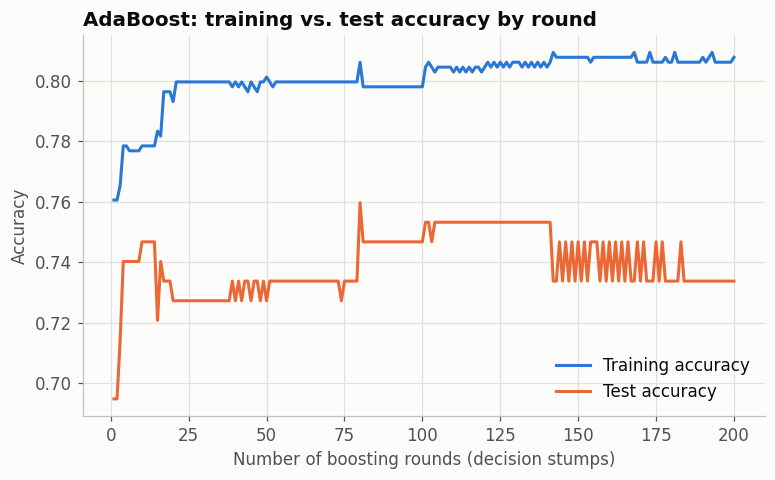

In [11]:
ada = make_pipe(AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=200, learning_rate=0.5, random_state=RANDOM_STATE)).fit(X_train, y_train)

ada_prep = ada.named_steps["prep"]
ada_model = ada.named_steps["model"]
Xtr_a, Xte_a = ada_prep.transform(X_train), ada_prep.transform(X_test)

print("First 5 stumps - weighted error and vote weight:")
display(pd.DataFrame({"weighted error": ada_model.estimator_errors_[:5].round(3),
                      "vote weight": ada_model.estimator_weights_[:5].round(3)},
                     index=[f"stump {i}" for i in range(1, 6)]))
print("Last 3 stumps' weighted error:", ada_model.estimator_errors_[-3:].round(3))

ada_train = ada.score(X_train, y_train)
ada_test = ada.score(X_test, y_test)
results["AdaBoost (stumps)"] = ada_test
print(f"\nAdaBoost train accuracy: {ada_train:.3f}")
print(f"AdaBoost test accuracy : {ada_test:.3f}")
print(f"Train - test gap       : {ada_train - ada_test:+.3f}\n")
print(classification_report(y_test, ada.predict(X_test), target_names=TARGET_NAMES, digits=3))

train_curve = list(ada_model.staged_score(Xtr_a, y_train))
test_curve_ada = list(ada_model.staged_score(Xte_a, y_test))
rounds = np.arange(1, len(train_curve) + 1)
best_round = int(np.argmax(test_curve_ada)) + 1
print(f"Best test accuracy {max(test_curve_ada):.3f} reached at round {best_round}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(rounds, train_curve, color=BLUE, label="Training accuracy")
ax.plot(rounds, test_curve_ada, color=ORANGE, label="Test accuracy")
ax.set_xlabel("Number of boosting rounds (decision stumps)"); ax.set_ylabel("Accuracy")
ax.set_title("AdaBoost: training vs. test accuracy by round")
ax.legend(frameon=False, loc="lower right")
plt.show()

### Task 8 (extension) – Do hyperparameters change the generalisation gap?

The analysis asks how hyperparameter adjustments can mitigate overfitting, so this cell backs that answer with evidence.

#### What the following code cell does
* Trains AdaBoost with several combinations of **base-tree depth** (stumps vs. slightly deeper trees) and **`learning_rate`** (1.0, 0.5, 0.1), each with 200 rounds.
* Records training accuracy, test accuracy, and their gap for each configuration in one table..

In [12]:
configs = [(1, 1.0), (1, 0.5), (1, 0.1), (2, 0.5), (3, 0.5)]
rows = []
for depth, lr in configs:
    m = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=depth),
                           n_estimators=200, learning_rate=lr,
                           random_state=RANDOM_STATE).fit(Xtr_a, y_train)
    tr, te = m.score(Xtr_a, y_train), m.score(Xte_a, y_test)
    rows.append({"tree depth": depth, "learning rate": lr, "train acc": round(tr, 3),
                 "test acc": round(te, 3), "gap (train - test)": round(tr - te, 3)})
display(pd.DataFrame(rows))

,tree depth,learning rate,train acc,test acc,gap (train - test)
0,1,1.0,0.822,0.760,0.063
1,1,0.5,0.808,0.734,0.074
2,1,0.1,0.780,0.747,0.033
3,2,0.5,0.829,0.727,0.102
4,3,0.5,0.907,0.740,0.167


(Extra) I decided to include the results from 4-8 as a summary for review

Summary of all models (wrap-up)

### What the following code cell does
Collects the test accuracy stored in the `results` dictionary by Tasks 4–8, prints them sorted, and draws one horizontal bar chart. Ensembles are highlighted in blue and the single-model references (the baseline Logistic Regression and the single decision tree) are shown in grey.

### How to read it
Because the test set has only 154 patients, differences of one or two percentage points are within noise. Look for the overall pattern (do ensembles help, and by roughly how much) rather than for a precise winner. The five analysis questions in `analysis.ipynb` build on these results.

Bagging (200 trees)               0.740
Hard Voting                       0.740
Soft Voting                       0.734
AdaBoost (stumps)                 0.734
Random Forest                     0.734
Logistic Regression (baseline)    0.708
Single Decision Tree              0.669


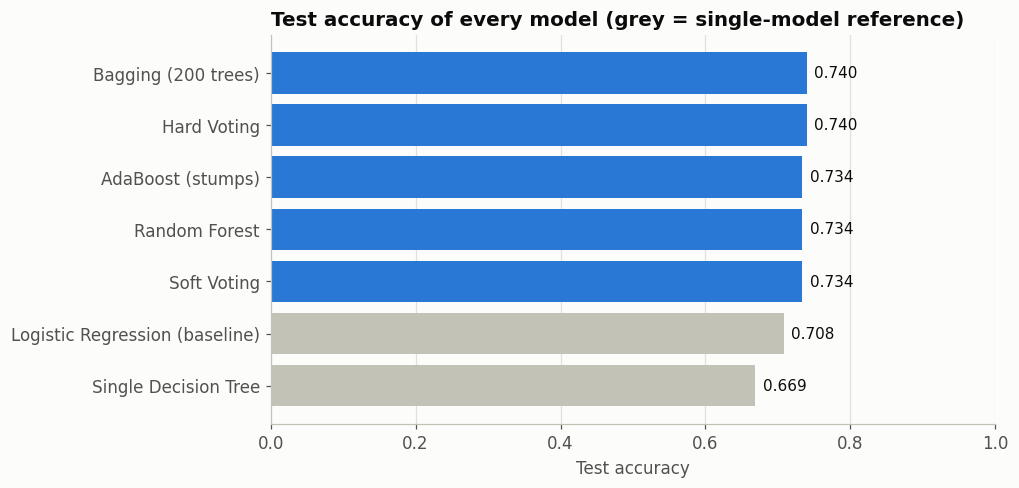

In [13]:
summary = pd.Series(results).sort_values()
print(summary.sort_values(ascending=False).round(3).to_string())

single_refs = {"Logistic Regression (baseline)", "Single Decision Tree"}
fig, ax = plt.subplots(figsize=(8.5, 4.6))
bars = ax.barh(summary.index, summary.values,
               color=[NEUTRAL if n in single_refs else BLUE for n in summary.index])
for b in bars:
    ax.text(b.get_width() + 0.01, b.get_y() + b.get_height() / 2, f"{b.get_width():.3f}", va="center", fontsize=10)
ax.set_xlim(0, 1); ax.set_xlabel("Test accuracy")
ax.set_title("Test accuracy of every model (grey = single-model reference)")
ax.grid(axis="y", visible=False)
plt.show()